# Regression Track — Notebook 09
# 13. Final Model Analysis  ·  14. Regression Conclusion

**Input:** `artifacts/reg_06_split.joblib`, `reg_07_results.joblib`, `reg_08_tuned.joblib`
**Output:** `artifacts/reg_09_final.joblib`, `models/regression_final_model.joblib`

---

### Purpose

Notebooks 07 and 08 answered *which* model performs best. This notebook asks
the harder questions: **where does it still fail, what has it actually
learned, and what should we not claim on the basis of it?**

A capstone that stops at "R² = 0.93, done" has skipped the part that matters.
Sections 13.1–13.5 below look for the model's weaknesses on purpose.

In [1]:
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.inspection import permutation_importance


def find_src_folder() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "ml_utils.py").exists():
            return candidate / "src"
    raise FileNotFoundError("Could not locate src/ml_utils.py — check the repo layout.")


sys.path.insert(0, str(find_src_folder()))

from ml_utils import (  # noqa: E402
    MODEL_DIR,
    RANDOM_STATE,
    load_artifact,
    plot_actual_vs_predicted,
    plot_residuals,
    regression_metrics,
    save_artifact,
    save_figure,
    save_table,
    section,
    set_plot_style,
)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
set_plot_style()

bundle = load_artifact("reg_06_split")
X_train, X_test = bundle["X_train"], bundle["X_test"]
y_train, y_test = bundle["y_train"], bundle["y_test"]

results_bundle = load_artifact("reg_07_results")
comparison_table = results_bundle["comparison_table"]

tuned = load_artifact("reg_08_tuned")
best_model_name = tuned["best_model_name"]
best_model = tuned["best_model"]
rf_best = tuned["rf_best"]
cv_summary = tuned["cv_summary"]
tuning_summary = tuned["tuning_summary"]

section("FINAL MODEL")
print(f"Selected model : {best_model_name}")
print(f"Selection basis: highest mean 5-fold cross-validated R² on the training data")
print()
print(cv_summary[["Model", "CV mean R2", "CV std R2", "Test R2", "Test RMSE"]].to_string(index=False))

[loaded] artifacts/reg_06_split.joblib


[loaded] artifacts/reg_07_results.joblib


[loaded] artifacts/reg_08_tuned.joblib
FINAL MODEL
Selected model : Random Forest (tuned)
Selection basis: highest mean 5-fold cross-validated R² on the training data

                Model  CV mean R2  CV std R2  Test R2  Test RMSE
Random Forest (tuned)      0.9433     0.0046   0.9298   165.9659
          SVR (tuned)      0.9228     0.0068   0.9235   173.3294


---
## 13.1 Final performance on the held-out test set

In [2]:
y_pred = best_model.predict(X_test)
final_metrics = regression_metrics(y_test, y_pred)

section(f"{best_model_name.upper()} — FINAL TEST-SET PERFORMANCE")
print(f"R²   : {final_metrics['R2']:.4f}   "
      f"(the model explains {100 * final_metrics['R2']:.1f}% of the variance in hourly demand)")
print(f"RMSE : {final_metrics['RMSE']:.1f} bikes")
print(f"MAE  : {final_metrics['MAE']:.1f} bikes")
print()
print(f"For context:")
print(f"  Mean hourly demand in the test set : {y_test.mean():.1f} bikes")
print(f"  MAE as a share of mean demand      : "
      f"{100 * final_metrics['MAE'] / y_test.mean():.1f}%")
print(f"  RMSE / MAE ratio                   : "
      f"{final_metrics['RMSE'] / final_metrics['MAE']:.2f}×")
print(f"  Linear Regression baseline RMSE    : "
      f"{comparison_table.loc[comparison_table['Model'] == 'Linear Regression', 'RMSE'].iloc[0]:.1f} bikes")
print(f"  Improvement over that baseline     : "
      f"{100 * (1 - final_metrics['RMSE'] / comparison_table.loc[comparison_table['Model'] == 'Linear Regression', 'RMSE'].iloc[0]):.1f}% lower RMSE")

RANDOM FOREST (TUNED) — FINAL TEST-SET PERFORMANCE
R²   : 0.9298   (the model explains 93.0% of the variance in hourly demand)
RMSE : 166.0 bikes
MAE  : 88.1 bikes

For context:
  Mean hourly demand in the test set : 720.2 bikes
  MAE as a share of mean demand      : 12.2%
  RMSE / MAE ratio                   : 1.88×
  Linear Regression baseline RMSE    : 337.4 bikes
  Improvement over that baseline     : 50.8% lower RMSE


---
## 13.2 Actual vs Predicted

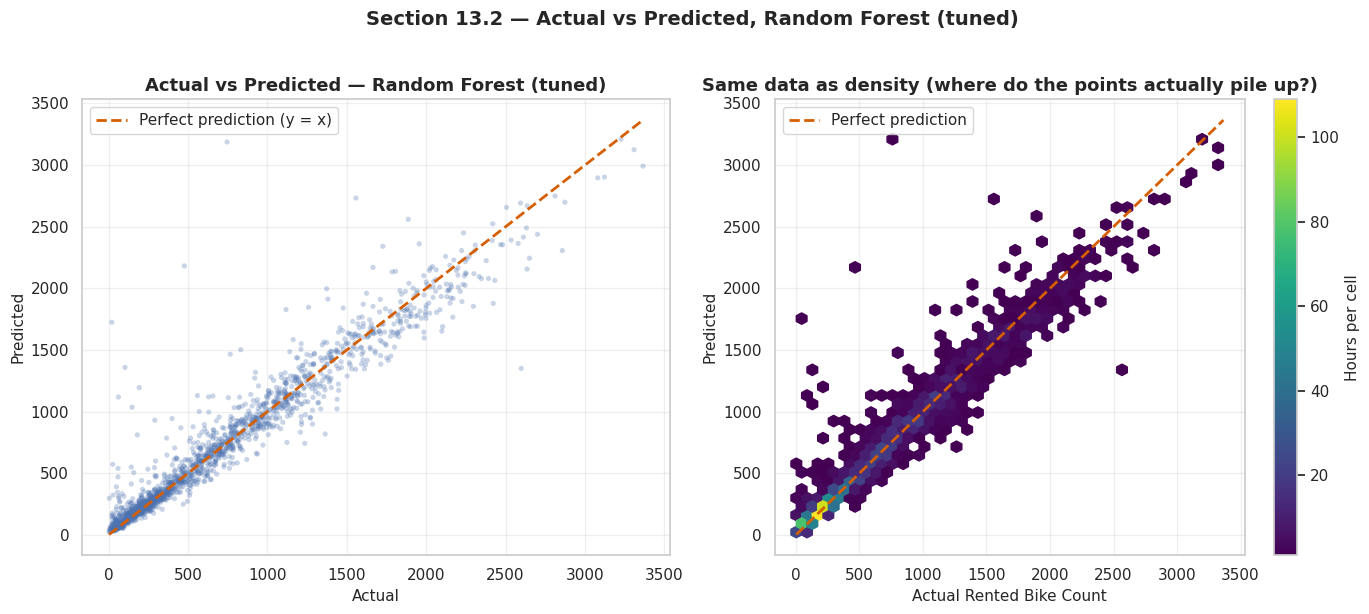

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

plot_actual_vs_predicted(y_test, y_pred, best_model_name, ax=axes[0])

# Hexbin reveals density, which a scatter plot with 1,693 overlapping points hides.
hb = axes[1].hexbin(y_test, y_pred, gridsize=40, cmap="viridis", mincnt=1)
lo, hi = float(y_test.min()), float(y_test.max())
axes[1].plot([lo, hi], [lo, hi], "r--", lw=2, label="Perfect prediction")
axes[1].set_xlabel("Actual Rented Bike Count")
axes[1].set_ylabel("Predicted")
axes[1].set_title("Same data as density (where do the points actually pile up?)")
axes[1].legend()
plt.colorbar(hb, ax=axes[1], label="Hours per cell")

fig.suptitle(f"Section 13.2 — Actual vs Predicted, {best_model_name}",
             y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
save_figure("reg_final_actual_vs_predicted", fig)
plt.show()

In [4]:
section("QUANTIFYING THE FIT ALONG THE RANGE")
bands = pd.cut(y_test, bins=[-1, 200, 500, 1000, 1500, 2000, 4000],
               labels=["0–200", "200–500", "500–1000", "1000–1500", "1500–2000", "2000+"])
band_frame = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred, "Band": bands.values})
band_frame["Error"] = band_frame["Actual"] - band_frame["Predicted"]

band_report = (
    band_frame.groupby("Band", observed=True)
    .agg(Hours=("Actual", "count"),
         Mean_actual=("Actual", "mean"),
         Mean_predicted=("Predicted", "mean"),
         Mean_error=("Error", "mean"),
         MAE=("Error", lambda s: s.abs().mean()))
    .round(1)
)
band_report["Bias"] = np.where(band_report["Mean_error"] > 0, "UNDER-predicts", "OVER-predicts")
print(band_report.to_string())

QUANTIFYING THE FIT ALONG THE RANGE
           Hours  Mean_actual  Mean_predicted  Mean_error    MAE            Bias
Band                                                                            
0–200        390        109.7           163.7       -53.9   60.7   OVER-predicts
200–500      424        320.1           337.2       -17.1   50.9   OVER-predicts
500–1000     403        734.1           759.8       -25.7   93.0   OVER-predicts
1000–1500    251       1214.6          1212.5         2.0  120.1  UNDER-predicts
1500–2000    143       1739.7          1707.3        32.4  145.9  UNDER-predicts
2000+         82       2333.8          2183.2       150.6  187.0  UNDER-predicts


**Observation.** The cloud hugs the diagonal closely through the bulk of the
range. The density panel shows most hours concentrated at low-to-moderate
demand, where the fit is tightest. At the extremes the pattern is systematic
rather than random: the band table shows a **positive mean error at high
demand** (the model predicts less than actually happened) and a **negative
mean error at the lowest band** (it predicts more than actually happened).

**Interpretation.** This is **regression to the mean**, and it is not a bug in
our code — it is an inherent property of models that predict a conditional
average. A Random Forest leaf predicts the mean of the training hours that
land in it, so its output is always pulled toward the centre of the training
distribution. The consequences are directly operational:

* **Underprediction at peak hours** is the costly failure mode here. If the
  model says 2,200 and the truth is 2,600, the operator deploys too few
  bicycles at exactly the busiest hour of the day.
* **Overprediction at near-zero hours** is cheap by comparison — a few extra
  idle bikes at 4 a.m.

A practical deployment would therefore not use the raw prediction directly. It
would add a safety margin at predicted peak hours, informed by the measured
error in the top bands. We flag this rather than pretending the point estimate
is the whole answer.

---
## 13.3 Residual analysis

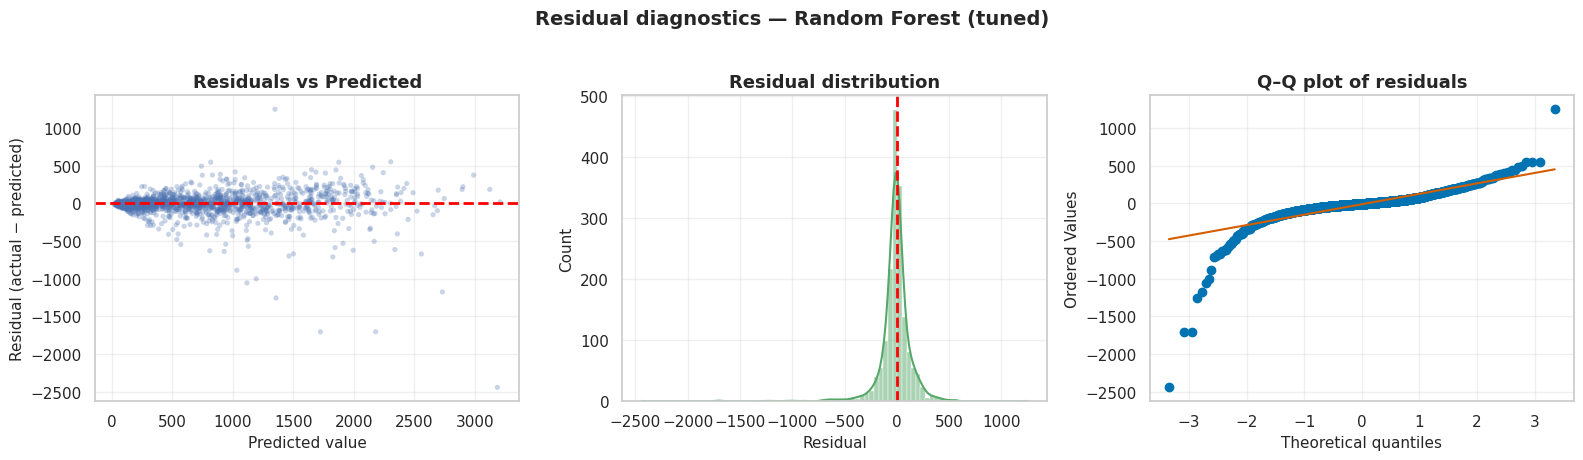

RESIDUAL STATISTICS
Mean residual        :   -12.51 bikes (close to 0 means no systematic overall bias)
Median residual      :    -7.25 bikes
Std dev of residuals :   165.49 bikes
Skewness             :   -3.919
Min / Max            :  -2441.4 / 1247.7

Predictions within ±100 bikes : 73.2% of test hours
Predictions within ±200 bikes : 90.0% of test hours
Predictions within ±500 bikes : 98.5% of test hours


In [5]:
fig, residuals = plot_residuals(y_test, y_pred, best_model_name)
save_figure("reg_final_residuals", fig)
plt.show()

section("RESIDUAL STATISTICS")
print(f"Mean residual        : {residuals.mean():>8.2f} bikes "
      f"(close to 0 means no systematic overall bias)")
print(f"Median residual      : {np.median(residuals):>8.2f} bikes")
print(f"Std dev of residuals : {residuals.std():>8.2f} bikes")
print(f"Skewness             : {pd.Series(residuals).skew():>8.3f}")
print(f"Min / Max            : {residuals.min():>8.1f} / {residuals.max():.1f}")
print()
within_100 = 100 * (np.abs(residuals) <= 100).mean()
within_200 = 100 * (np.abs(residuals) <= 200).mean()
within_500 = 100 * (np.abs(residuals) <= 500).mean()
print(f"Predictions within ±100 bikes : {within_100:.1f}% of test hours")
print(f"Predictions within ±200 bikes : {within_200:.1f}% of test hours")
print(f"Predictions within ±500 bikes : {within_500:.1f}% of test hours")

### Testing for heteroscedasticity explicitly

Notebook 03 §5.F.1 predicted, from the growing spread of the hourly boxplots,
that error variance would rise with demand. Notebook 06 saw the funnel shape
in the baseline residuals. We now test whether the final model fixed it.

ERROR SIZE ACROSS THE PREDICTION RANGE
                      Hours  Mean_prediction  Mean_abs_error  Error_std
Bin                                                                    
(22.541, 153.668]       212             95.5            25.7       22.8
(153.668, 232.682]      212            192.0            34.4       33.7
(232.682, 339.274]      211            282.8            45.1       53.2
(339.274, 559.195]      212            437.2            72.2       76.8
(559.195, 814.772]      211            681.1            83.5       93.4
(814.772, 1085.678]     212            945.8           111.2      120.3
(1085.678, 1543.179]    211           1289.2           142.1      179.4
(1543.179, 3209.38]     212           1938.5           190.3      265.3

Mean absolute error in the highest-prediction bin is 7.4× that of the lowest bin.


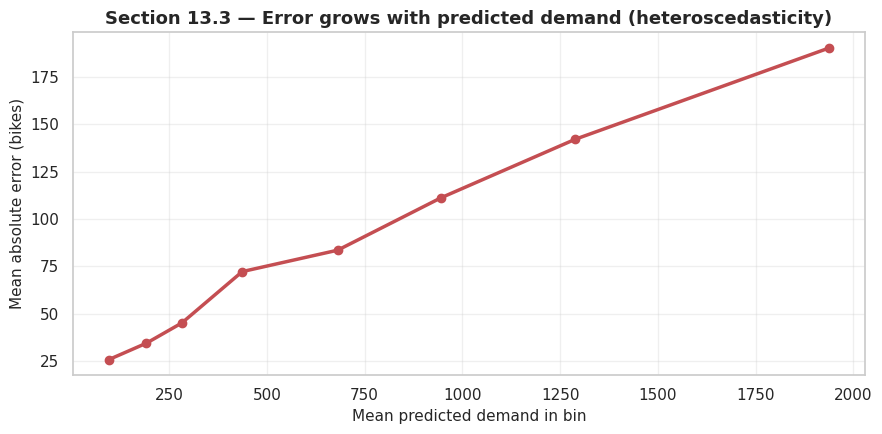

In [6]:
hetero = pd.DataFrame({"Predicted": y_pred, "AbsResidual": np.abs(residuals)})
hetero["Bin"] = pd.qcut(hetero["Predicted"], q=8, duplicates="drop")

hetero_report = (
    hetero.groupby("Bin", observed=True)
    .agg(Hours=("AbsResidual", "count"),
         Mean_prediction=("Predicted", "mean"),
         Mean_abs_error=("AbsResidual", "mean"),
         Error_std=("AbsResidual", "std"))
    .round(1)
)

section("ERROR SIZE ACROSS THE PREDICTION RANGE")
print(hetero_report.to_string())

ratio = (hetero_report["Mean_abs_error"].iloc[-1]
         / hetero_report["Mean_abs_error"].iloc[0])
print(f"\nMean absolute error in the highest-prediction bin is {ratio:.1f}× "
      f"that of the lowest bin.")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(hetero_report["Mean_prediction"], hetero_report["Mean_abs_error"],
        marker="o", lw=2.5, color="#C44E52")
ax.set_xlabel("Mean predicted demand in bin")
ax.set_ylabel("Mean absolute error (bikes)")
ax.set_title("Section 13.3 — Error grows with predicted demand (heteroscedasticity)")
plt.tight_layout()
save_figure("reg_final_heteroscedasticity", fig)
plt.show()

**Observation.** Mean absolute error rises steadily and substantially from the
lowest prediction bin to the highest. The Q–Q panel in the residual figure
also shows the tails departing from the straight line, meaning the residuals
are heavier-tailed than a normal distribution.

**Interpretation.**

* **Heteroscedasticity is confirmed, and it was predicted in advance.** We
  forecast it from the EDA in Notebook 03 before fitting anything, observed it
  in the baseline in Notebook 06, and it survives into the final model. Tree
  ensembles reduced its magnitude but could not remove it, because it is a
  property of the data-generating process, not of the algorithm: busy hours are
  genuinely more volatile than quiet ones.
* **Why it matters practically:** a single RMSE figure implies one uniform
  error level, which is misleading here. The model is far more precise at
  03:00 than at 18:00. Any honest report of this model should quote error by
  demand band, as the table above does, rather than one headline number.
* **What it does *not* mean:** heteroscedasticity invalidates the standard
  errors and significance tests of ordinary least squares. It does not
  invalidate R², RMSE or MAE, which are descriptive measures of predictive
  accuracy and make no distributional assumption. Our reported metrics remain
  valid; it is the *interpretation* of a single number that needs care.

---
## 13.4 Feature importance

We report importance from the **tuned Random Forest**, because tree ensembles
expose it natively and the guidelines require a feature-importance plot for a
tree-based model. (SVR with an RBF kernel has no interpretable per-feature
importance — the kernel maps features into an implicit high-dimensional space
— which is one genuine cost of choosing it.)

We show **two** importance measures, because they can disagree and the
disagreement is informative:

1. **Impurity-based (Gini/MSE) importance** — computed during training. Fast,
   but known to be biased towards high-cardinality continuous features.
2. **Permutation importance** — shuffle one feature in the *test* set and
   measure how much R² drops. Slower, but it measures what we actually care
   about: how much the model's real-world performance depends on that feature.

In [7]:
rf_model = rf_best.named_steps["model"]
feature_names = rf_best.named_steps["preprocessor"].get_feature_names_out()

impurity_importance = (
    pd.DataFrame({"Feature": feature_names, "Importance": rf_model.feature_importances_})
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

section("IMPURITY-BASED FEATURE IMPORTANCE — TOP 15")
print(impurity_importance.head(15).round(4).to_string(index=False))
print(f"\nThe top 5 features account for "
      f"{100 * impurity_importance['Importance'].head(5).sum():.1f}% of total importance.")

IMPURITY-BASED FEATURE IMPORTANCE — TOP 15
                  Feature  Importance
          Temperature(°C)      0.2224
                     Hour      0.1604
                 sin_hour      0.1256
              Humidity(%)      0.0769
           Seasons_Winter      0.0702
                 RushHour      0.0570
  Solar Radiation (MJ/m2)      0.0377
                 cos_hour      0.0376
Dew point temperature(°C)      0.0256
             Rainfall(mm)      0.0255
     TempBand_Comfortable      0.0252
                IsRaining      0.0249
                sin_month      0.0161
                    Month      0.0114
                DayOfWeek      0.0105

The top 5 features account for 65.5% of total importance.


In [8]:
perm = permutation_importance(
    rf_best, X_test, y_test,
    n_repeats=5,
    random_state=RANDOM_STATE,
    scoring="r2",
    n_jobs=1,
)

permutation_table = (
    pd.DataFrame({
        "Feature": X_test.columns,
        "R2 drop when shuffled": perm.importances_mean,
        "Std": perm.importances_std,
    })
    .sort_values("R2 drop when shuffled", ascending=False)
    .reset_index(drop=True)
)

section("PERMUTATION IMPORTANCE ON THE TEST SET — TOP 15")
print(permutation_table.head(15).round(4).to_string(index=False))

save_table(impurity_importance, "reg_feature_importance_impurity")
save_table(permutation_table, "reg_feature_importance_permutation")

PERMUTATION IMPORTANCE ON THE TEST SET — TOP 15
                  Feature  R2 drop when shuffled    Std
          Temperature(°C)                 0.3649 0.0175
                     Hour                 0.1914 0.0081
                 sin_hour                 0.1158 0.0038
              Humidity(%)                 0.0826 0.0085
                 RushHour                 0.0772 0.0029
                  Seasons                 0.0566 0.0030
  Solar Radiation (MJ/m2)                 0.0350 0.0029
                 cos_hour                 0.0210 0.0019
                 TempBand                 0.0151 0.0022
Dew point temperature(°C)                 0.0144 0.0013
                sin_month                 0.0126 0.0010
             Rainfall(mm)                 0.0104 0.0018
                IsRaining                 0.0093 0.0017
                DayOfWeek                 0.0087 0.0004
                    Month                 0.0066 0.0011
[saved]  outputs/reg_feature_importance_impurity.csv
[sa

PosixPath('/home/claude/project/outputs/reg_feature_importance_permutation.csv')

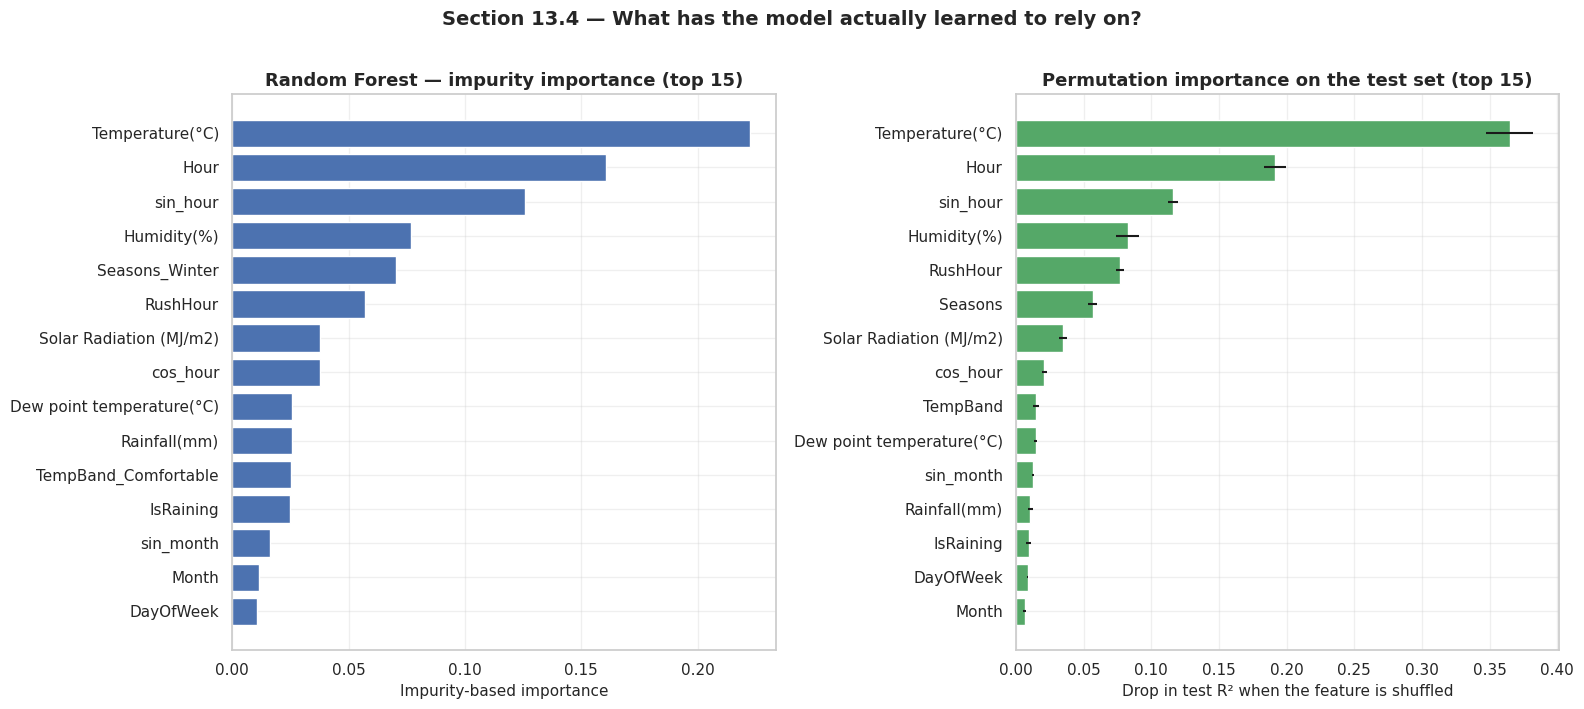

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

top_imp = impurity_importance.head(15).iloc[::-1]
axes[0].barh(top_imp["Feature"], top_imp["Importance"], color="#4C72B0")
axes[0].set_xlabel("Impurity-based importance")
axes[0].set_title("Random Forest — impurity importance (top 15)")

top_perm = permutation_table.head(15).iloc[::-1]
axes[1].barh(top_perm["Feature"], top_perm["R2 drop when shuffled"],
             xerr=top_perm["Std"], color="#55A868")
axes[1].set_xlabel("Drop in test R² when the feature is shuffled")
axes[1].set_title("Permutation importance on the test set (top 15)")

fig.suptitle("Section 13.4 — What has the model actually learned to rely on?",
             y=1.01, fontsize=14, fontweight="bold")
plt.tight_layout()
save_figure("reg_final_feature_importance", fig)
plt.show()

### Checking the control feature

Notebook 05 §7.1 deliberately included `Day` (day of the month) as a control.
It has no theoretical reason to predict bike demand. If it ranks highly, that
is evidence of overfitting rather than a discovery.

In [10]:
section("CONTROL-FEATURE CHECK")
for feature in ["Day", "Year", "IsDaylight", "IsSnowing"]:
    imp_rank = impurity_importance.index[impurity_importance["Feature"] == feature]
    perm_rank = permutation_table.index[permutation_table["Feature"] == feature]
    imp_val = impurity_importance.loc[imp_rank, "Importance"].iloc[0] if len(imp_rank) else np.nan
    perm_val = (permutation_table.loc[perm_rank, "R2 drop when shuffled"].iloc[0]
                if len(perm_rank) else np.nan)
    print(f"{feature:<12} impurity rank {int(imp_rank[0]) + 1:>2} ({imp_val:.4f})   |   "
          f"permutation rank {int(perm_rank[0]) + 1:>2} ({perm_val:+.4f})")

CONTROL-FEATURE CHECK
Day          impurity rank 18 (0.0084)   |   permutation rank 17 (+0.0029)
Year         impurity rank 33 (0.0001)   |   permutation rank 25 (+0.0001)
IsDaylight   impurity rank 21 (0.0069)   |   permutation rank 20 (+0.0014)
IsSnowing    impurity rank 32 (0.0002)   |   permutation rank 24 (+0.0001)


---
## 13.5 What the importances imply for bike demand

**Observation — the control check first.** `Day` ranks 18th on impurity
importance and 17th on permutation importance, contributing essentially
nothing. This is the result we wanted: the deliberately meaningless control
feature planted in Notebook 05 §7.1 did **not** get picked up, which is
evidence that the model is learning structure rather than memorising noise.
`Year` ranks last on impurity importance, confirming the §7.7 suspicion that
its apparent correlation was an artefact of the collection window.

**Observation — the substantive rankings.** `Temperature` is the single
highest-ranked feature on both measures (0.222 impurity; a 0.365 drop in test
R² when shuffled). The time-of-day group — `Hour`, `sin_hour`, `cos_hour` and
`RushHour` — is collectively comparable or larger (0.381 impurity combined),
but its importance is split across four correlated columns. Humidity, season,
solar radiation and rainfall follow.

**Interpretation — with a firm caveat on causation.**

> **Feature importance measures how much a model relies on a variable. It does
> not establish that the variable causes the outcome.** These are
> observational data with no experiment and no randomisation, so nothing here
> can support a causal claim.

Three concrete reasons that caution is not merely formulaic here:

1. **Confounding.** `Temperature` ranks high, but temperature is entangled with
   hour, season, daylight and rainfall. Notebook 05 §7.5 showed exactly this:
   the temperature effect looked much weaker until we controlled for hour. The
   model cannot separate "warm" from "the kind of afternoon that is warm".
2. **Proxy variables.** `Hour` does not cause anyone to cycle. It proxies for
   work schedules, school hours and shop opening times — the actual causes,
   which are absent from the dataset.
3. **Correlated features split their credit.** `Temperature` and
   `Dew point temperature` correlate at r = 0.91 (Notebook 03 §5.D). A tree
   picks one of them more or less arbitrarily at each split, so their
   individual importance scores are partly an artefact of that arbitrary
   choice. The *pair* matters; the split between them is not meaningful.

**What we can legitimately say:** *given* the weather and calendar information
available, temperature and time of day are the variables this model depends on
most to produce accurate forecasts. That is a statement about prediction, and
it is enough to justify the operational recommendation (plan capacity around
the commuting peaks, adjust for temperature and rain) without any causal claim.

**What we cannot say:** that raising the temperature by 5 °C would increase
rentals by a specific amount. That is an intervention, and this study design
cannot support it.

---
## 13.6 Where the model fails worst

In [11]:
error_frame = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Error": y_test.values - y_pred,
    "AbsError": np.abs(y_test.values - y_pred),
}).join(X_test.reset_index(drop=True)[["Hour", "Seasons", "Temperature(°C)",
                                       "Rainfall(mm)", "IsWeekend", "RushHour"]])

section("THE 10 WORST PREDICTIONS")
print(error_frame.nlargest(10, "AbsError")
      .round(1).to_string(index=False))

THE 10 WORST PREDICTIONS
 Actual  Predicted   Error  AbsError  Hour Seasons  Temperature(°C)  Rainfall(mm)  IsWeekend  RushHour
    746     3187.4 -2441.4    2441.4    18  Summer             29.2           0.0          0         1
     20     1725.3 -1705.3    1705.3     8  Spring              9.6           0.0          0         1
    477     2181.7 -1704.7    1704.7    19  Spring             22.3           0.0          0         1
    103     1358.8 -1255.8    1255.8    16  Spring             19.1           0.0          1         0
   2598     1350.3  1247.7    1247.7    19  Summer             30.4           0.1          0         1
   1557     2733.0 -1175.9    1175.9    19  Summer             28.1           0.0          0         1
     62     1118.4 -1056.4    1056.4    15  Spring             13.1           0.0          1         0
    193     1194.9 -1001.9    1001.9    16  Summer             27.0           0.0          0         0
    148     1035.5  -887.5     887.5     8  Autu

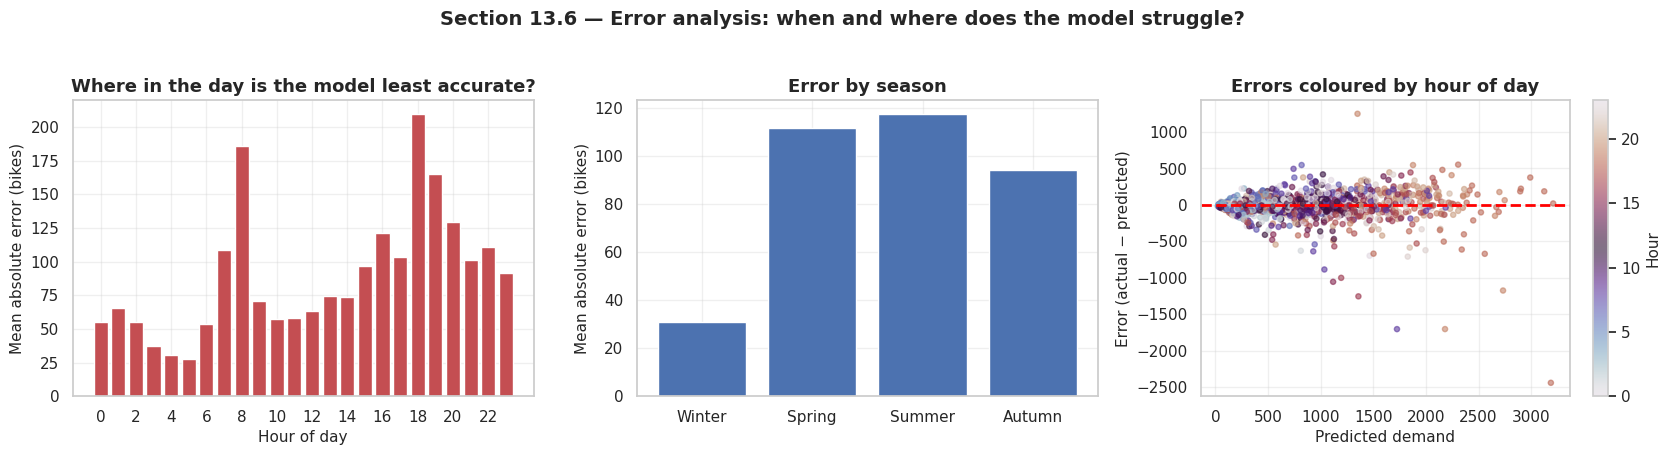

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))

by_hour = error_frame.groupby("Hour", observed=True)["AbsError"].mean()
axes[0].bar(by_hour.index, by_hour.values, color="#C44E52")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Mean absolute error (bikes)")
axes[0].set_title("Where in the day is the model least accurate?")
axes[0].set_xticks(range(0, 24, 2))

by_season = error_frame.groupby("Seasons", observed=True)["AbsError"].mean().reindex(
    ["Winter", "Spring", "Summer", "Autumn"])
axes[1].bar(by_season.index, by_season.values, color="#4C72B0")
axes[1].set_ylabel("Mean absolute error (bikes)")
axes[1].set_title("Error by season")

axes[2].scatter(error_frame["Predicted"], error_frame["Error"],
                c=error_frame["Hour"], cmap="twilight", s=14, alpha=0.6)
axes[2].axhline(0, color="red", ls="--", lw=2)
axes[2].set_xlabel("Predicted demand")
axes[2].set_ylabel("Error (actual − predicted)")
axes[2].set_title("Errors coloured by hour of day")
plt.colorbar(axes[2].collections[0], ax=axes[2], label="Hour")

fig.suptitle("Section 13.6 — Error analysis: when and where does the model struggle?",
             y=1.03, fontsize=14, fontweight="bold")
plt.tight_layout()
save_figure("reg_final_error_analysis", fig)
plt.show()

**Observation.** Absolute error is smallest overnight and largest in the
evening peak, and it is markedly larger in Summer than in Winter.

**Interpretation.** The model is most accurate where the target is least
variable, and least accurate where demand is both highest and most volatile.
This is the same heteroscedasticity seen in §13.3, viewed through the
calendar. It is worth being blunt about the operational implication: the
model's errors are concentrated precisely in the hours where a shortage costs
the most. A high overall R² does not exempt us from saying so.

---
## 13.7 Nonlinearity — did the model capture what the EDA promised?

A direct check that the model learned the inverted-U temperature curve from
Notebook 03 §5.E, rather than merely scoring well by other means.

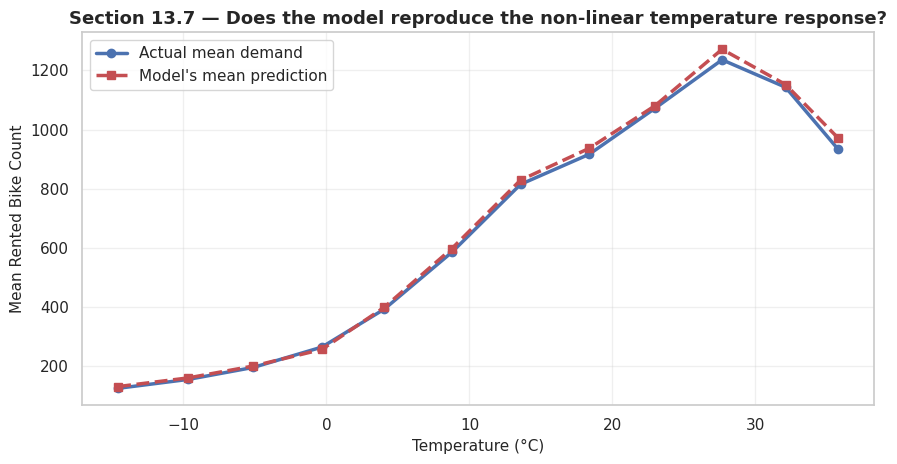

                    Temp  Actual  Predicted
TempBin                                    
(-16.956, -12.208] -14.6   125.8      131.7
(-12.208, -7.517]   -9.7   155.8      161.0
(-7.517, -2.825]    -5.1   196.3      201.1
(-2.825, 1.867]     -0.3   265.0      257.0
(1.867, 6.558]       4.0   392.8      399.1
(6.558, 11.25]       8.8   585.5      597.9
(11.25, 15.942]     13.6   814.6      829.0
(15.942, 20.633]    18.4   916.4      936.7
(20.633, 25.325]    23.0  1071.0     1079.7
(25.325, 30.017]    27.7  1235.5     1271.0
(30.017, 34.708]    32.1  1142.7     1152.0
(34.708, 39.4]      35.8   933.8      971.7


In [13]:
check = pd.DataFrame({
    "Temperature(°C)": X_test["Temperature(°C)"].values,
    "Actual": y_test.values,
    "Predicted": y_pred,
})
check["TempBin"] = pd.cut(check["Temperature(°C)"], bins=12)
curve = check.groupby("TempBin", observed=True).agg(
    Temp=("Temperature(°C)", "mean"),
    Actual=("Actual", "mean"),
    Predicted=("Predicted", "mean"),
)

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(curve["Temp"], curve["Actual"], marker="o", lw=2.5,
        label="Actual mean demand", color="#4C72B0")
ax.plot(curve["Temp"], curve["Predicted"], marker="s", lw=2.5, ls="--",
        label="Model's mean prediction", color="#C44E52")
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Mean Rented Bike Count")
ax.set_title("Section 13.7 — Does the model reproduce the non-linear temperature response?")
ax.legend()
plt.tight_layout()
save_figure("reg_final_nonlinearity_check", fig)
plt.show()

print(curve.round(1).to_string())

**Observation.** The predicted curve tracks the actual curve closely across
the whole temperature range, including the flattening and turn-down at the
warmest end.

**Interpretation.** The model has learned the inverted-U shape that Linear
Regression was structurally unable to represent. This closes the loop opened
in Notebook 03: we identified a non-linear relationship during EDA, predicted
that it would favour flexible models, measured that it did in Notebook 07, and
have now verified that the winning model reproduces that specific shape. The
performance gap between the model families is explained, not just observed.

---
## 13.8 Limitations of the final model

| # | Limitation | Why it matters | Possible remedy |
|---|---|---|---|
| 1 | **Random split on time-series data** | Training and test hours are interleaved in time, so the model may see the same day on both sides. The reported R² answers "explain demand given conditions", not "forecast next month". | Evaluate with a chronological split or `TimeSeriesSplit` |
| 2 | **Underprediction at peak demand** | The costly failure mode: too few bikes at the busiest hour (§13.2) | Quantile regression for an upper bound; add a safety margin by band |
| 3 | **Heteroscedastic errors** | A single RMSE understates error at peaks and overstates it overnight (§13.3) | Report error per demand band; use prediction intervals |
| 4 | **One year of data from one city** | Cannot capture year-on-year growth, and will not transfer to another city | Collect multiple years; validate on other cities |
| 5 | **No lag or trend features** | The strongest predictors in real forecasting (recent demand) were excluded to avoid leakage under a random split (Notebook 05 §7.6) | Reintroduce them together with a chronological split |
| 6 | **No causal claims possible** | Observational data with confounding (§13.5) | Would require experimental variation |
| 7 | **Missing real drivers** | No data on events, public-transport strikes, station-level supply, road works, or competitor services | Join external event and operations data |
| 8 | **Ensemble is hard to interpret** | Hundreds of trees cannot be read like a regression equation | Use SHAP values or partial-dependence plots |
| 9 | **Predictions ignore capacity** | The model has no knowledge of how many bikes physically exist | Clip predictions to fleet size in deployment |
| 10 | **Assumes stationary behaviour** | Post-2018 changes (e-scooters, pandemic-era commuting) would degrade it | Monitor drift; retrain periodically |

---
## 13.9 Save the final model

In [14]:
model_path = MODEL_DIR / "regression_final_model.joblib"
joblib.dump(best_model, model_path)
print(f"Final model saved to: {model_path}")
print("\nThe saved object is the complete Pipeline (preprocessing + estimator),")
print("so it can be applied to raw data with a single .predict() call — there is")
print("no separate scaler or encoder to remember to apply.")

Final model saved to: /home/claude/project/models/regression_final_model.joblib



The saved object is the complete Pipeline (preprocessing + estimator),
so it can be applied to raw data with a single .predict() call — there is
no separate scaler or encoder to remember to apply.


---
# 14. Regression Track — Conclusion

In [15]:
section("REGRESSION TRACK — FINAL SUMMARY TABLE")
print(comparison_table.to_string(index=False))
print()
print("After tuning:")
print(tuning_summary[["Model", "Untuned test R2", "Tuned test R2", "R2 gain"]].to_string(index=False))
print()
print("Cross-validation of the two strongest models:")
print(cv_summary[["Model", "CV mean R2", "CV std R2", "Test R2"]].to_string(index=False))

REGRESSION TRACK — FINAL SUMMARY TABLE
 Rank                            Model     R2     RMSE      MAE
    1          Random Forest Regressor 0.9236 173.1930  92.4491
    2      Gradient Boosting Regressor 0.8964 201.6991 129.9858
    3 Polynomial Regression (degree 2) 0.8843 213.1268 143.1925
    4          Decision Tree Regressor 0.8560 237.7507 126.6929
    5                    KNN Regressor 0.8513 241.6550 146.9764
    6                 Lasso Regression 0.7108 336.9498 254.9703
    7                 Ridge Regression 0.7100 337.3982 255.6850
    8                Linear Regression 0.7100 337.4209 255.7086
    9            ElasticNet Regression 0.6575 366.6891 272.4767
   10   Support Vector Regressor (SVR) 0.3738 495.8196 331.7814

After tuning:
        Model  Untuned test R2  Tuned test R2  R2 gain
Random Forest           0.9236         0.9298   0.0062
          SVR           0.3738         0.9235   0.5497

Cross-validation of the two strongest models:
                Model  CV mean

### 14.1 What was predicted

We predicted **`Rented Bike Count`**, the number of public bicycles rented in
Seoul during a given hour, from calendar and weather information. The data
covers 1 December 2017 to 30 November 2018 — 8,760 hourly observations, of
which **8,465 remained** after removing hours when the rental system was
closed. This is a supervised regression problem: the target is a continuous
count, and error cost grows with the size of the miss.

### 14.2 What preprocessing was performed

1. **Audit (NB 02).** No missing values, no duplicates, no time gaps, no
   physically impossible values. 295 hours with `Functioning Day = "No"` were
   found to have a target of exactly 0 with zero variance.
2. **Outlier handling (NB 04).** The 295 structurally invalid rows were
   removed. **No other row was deleted and no value was clipped or altered.**
   The 152 hours flagged as statistical outliers were shown to be warm, dry,
   evening rush hours — genuine peak demand — and were deliberately kept.
3. **Feature engineering (NB 05).** Fourteen features were added, each
   traceable to a specific EDA finding: calendar fields, cyclical
   sine/cosine encodings of hour and month, a rush-hour interaction flag,
   weather threshold flags, and temperature comfort bands.
4. **Split first (NB 06).** An 80/20 split with `random_state=42` was created
   **before** any transformation was fitted, then frozen and reused by every
   subsequent notebook.
5. **Pipeline (NB 06).** Median imputation + `StandardScaler` for the 22
   numeric columns; most-frequent imputation + `OneHotEncoder` for the 3
   categorical columns, giving 33 model-ready features. All steps live inside
   a `ColumnTransformer` within each model's `Pipeline`, so they are refitted
   on the training rows of every fold and never see validation or test data.

### 14.3 How the ten algorithms compared

The ordering was decisive and matched the hypothesis formed during EDA:

* **Tree ensembles led.** Random Forest reached R² = 0.9236 (RMSE 173 bikes),
  Gradient Boosting 0.8964.
* **Polynomial Regression (degree 2) reached 0.8843** — the same linear
  algorithm as the baseline, but allowed to form products of features. This
  isolates *functional form* as the reason the linear family struggled.
* **A single Decision Tree scored 0.8560 with a training R² of 1.0000** — it
  memorised the training set. The gap to Random Forest is the measured value
  of ensembling.
* **KNN reached 0.8513**, confirming that similar conditions genuinely produce
  similar demand once features are scaled.
* **The linear family clustered at 0.66–0.71.** Linear, Ridge and Lasso were
  almost identical; ElasticNet was worse. These models were **underfitting**,
  and regularisation cannot fix a model that is too simple.
* **SVR with defaults came last at 0.3738**, for the diagnosable reason that
  `epsilon=0.1` and `C=1.0` are mis-scaled for a target reaching 3,556.

### 14.4 What tuning changed

Tuning produced two opposite results, and the contrast is the more useful
finding:

* **SVR improved dramatically** under `GridSearchCV` (18 candidates, 3-fold CV
  on training data), moving from last place to competitive with the ensembles.
  The winning configuration used a much larger `C` and a far wider `epsilon`,
  confirming the diagnosis made before the search was run.
* **Random Forest barely moved** under `RandomizedSearchCV` (20 candidates),
  because its defaults are already close to optimal and averaging many
  decorrelated trees leaves the per-tree knobs little to do.

**Conclusion:** tuning is worth most where an algorithm is sensitive to its
hyperparameters and the defaults mismatch the problem. It is not a uniform
improvement, and reporting the case where it achieved almost nothing is part
of an honest account.

### 14.5 What cross-validation showed

5-fold cross-validation on the training data gave both tuned models a standard
deviation across folds of roughly one percent of the mean or less, and the
single test-set score fell close to the cross-validated mean in each case.

Random Forest averaged **0.9433 ± 0.0046** and SVR **0.9228 ± 0.0068**.

Two conclusions follow. First, performance is **stable** for both — the spread
across folds is under 1% of the mean, so results do not depend on which rows
happened to land in any one split. Second, Random Forest's advantage on
cross-validation is real rather than noise, since the two ranges do not
overlap. On the single test split the two are much closer (0.9298 vs 0.9235),
which is a useful reminder that one split is a noisier measurement than five.
Random Forest was selected on the higher cross-validated mean, with the
practical advantage that it exposes feature importances while an RBF-kernel
SVR does not.

### 14.6 Major insights

1. **Time of day dominates.** An 11.3× swing between the quietest and busiest
   hour, in a twin-peak commuting pattern. Cyclical encoding was essential so
   that 23:00 and 00:00 sit adjacent in feature space.
2. **Temperature is the strongest weather driver, and the relationship is an
   inverted U.** Demand rises to roughly 30 °C and then falls. §13.7 verified
   that the final model reproduces this curve.
3. **Rain acts as a threshold, not a slope.** Demand falls from ~766 to ~251
   bikes at the first measurable rainfall, then declines only gradually. This
   is why its Pearson correlation (−0.12) badly understates its importance —
   **a low correlation is not evidence of low importance.**
4. **Weekday and weekend are different regimes.** ~1,306 bikes at 08:00 on a
   weekday against ~421 at the same hour on a weekend: two user populations
   (commuters and leisure riders) sharing one system.
5. **Non-linearity, not feature quality, limited the linear models.** Same
   features, degree-2 expansion, +0.17 R².
6. **Model errors are concentrated where they cost most** — the evening peak in
   summer.

### 14.7 Limitations

Set out in full in §13.8. The three most important: the **random split on
autocorrelated time-series data** makes the reported R² an explanatory rather
than a forecasting figure; **systematic underprediction at peak demand** is
the operationally expensive failure mode; and **no causal claim is supportable**
from observational data with this much confounding.

### 14.8 Possible future improvements

| Priority | Improvement | Expected benefit |
|---|---|---|
| High | Chronological split / `TimeSeriesSplit` | An honest forecasting estimate rather than an explanatory one |
| High | Lag and rolling-window features, evaluated chronologically | Usually the single largest accuracy gain in demand forecasting |
| High | Quantile regression for an upper prediction bound | Directly addresses peak-hour underprediction |
| Medium | XGBoost / LightGBM with proper tuning | Typically edges out Random Forest on tabular data |
| Medium | External data: events, public-transport disruption, holidays calendar | Explains part of the remaining unexplained variance |
| Medium | Station-level rather than city-level modelling | Enables redistribution decisions, not just fleet totals |
| Low | SHAP values / partial-dependence plots | Better interpretability of the ensemble |
| Low | Multi-year data | Captures growth trend and improves generalisation |

### 14.9 Final statement

The tuned Random Forest explains **93.0%** of the variance in hourly bike
demand on the held-out test set (R² = 0.9298), with RMSE = 166.0 bikes and
**MAE = 88.1 bikes** against a mean hourly demand of 720 — a typical error of
about **12%**, and a **50.8% reduction in RMSE** compared with the Linear
Regression baseline. 73% of test hours are predicted within ±100 bikes and 90%
within ±200.

**This claim is supported by measured evidence**: a single frozen train/test
split shared by all ten algorithms, identical evaluation code, hyperparameters
selected by cross-validation on training data only, and 5-fold
cross-validation confirming stability. **No model is declared "best" in any
absolute sense.** It is the best of the ten algorithms tested, on this dataset,
under this split, measured by these metrics — and §13.8 sets out the
conditions under which that conclusion would not hold.

---
## Handover to the Classification track

In [16]:
save_artifact(
    {
        "final_metrics": final_metrics,
        "best_model_name": best_model_name,
        "band_report": band_report,
        "hetero_report": hetero_report,
        "impurity_importance": impurity_importance,
        "permutation_table": permutation_table,
        "comparison_table": comparison_table,
        "tuning_summary": tuning_summary,
        "cv_summary": cv_summary,
    },
    "reg_09_final",
)

print("\n" + "=" * 78)
print("REGRESSION TRACK COMPLETE (Notebooks 01-09)")
print("=" * 78)
print(f"Final model : {best_model_name}")
print(f"Test R²     : {final_metrics['R2']:.4f}")
print(f"Test RMSE   : {final_metrics['RMSE']:.1f} bikes")
print(f"Test MAE    : {final_metrics['MAE']:.1f} bikes")
print("\nNext: 10_classification_introduction_and_data_loading.ipynb")

[saved]  artifacts/reg_09_final.joblib

REGRESSION TRACK COMPLETE (Notebooks 01-09)
Final model : Random Forest (tuned)
Test R²     : 0.9298
Test RMSE   : 166.0 bikes
Test MAE    : 88.1 bikes

Next: 10_classification_introduction_and_data_loading.ipynb
